In [1]:

import os, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image

ROOT = '/kaggle/input/datasets/ashery/chexpert/'

df = pd.read_csv(os.path.join(ROOT, 'train.csv'))

LABELS = ['Cardiomegaly', 'Pleural Effusion', 'Atelectasis']

label_cols = df.columns[5:]  
# Remove macOS metadata files from the DataFrame
df = df[~df['Path'].str.contains(r'(^|/)\._', regex=True, na=False)].copy()

# Construct image paths
df['img_path'] = df['Path'].apply(
    lambda p: p if os.path.isabs(p)
    else os.path.join(ROOT, p.replace('CheXpert-v1.0-small/', '', 1))
)

# Verify paths
print("First CSV path:", df['Path'].iloc[0])
print("Constructed path:", df['img_path'].iloc[0])
print("Image exists:", os.path.exists(df['img_path'].iloc[0]))

/tmp/ipykernel_48/1311647318.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df = df[~df['Path'].str.contains(r'(^|/)\._', regex=True, na=False)].copy()


First CSV path: CheXpert-v1.0-small/train/patient00001/study1/view1_frontal.jpg
Constructed path: /kaggle/input/datasets/ashery/chexpert/train/patient00001/study1/view1_frontal.jpg
Image exists: True


In [2]:

'''# missing files
df['exists'] = [os.path.exists(p) for p in df.img_path]
print(df.exists.value_counts())'''

"# missing files\ndf['exists'] = [os.path.exists(p) for p in df.img_path]\nprint(df.exists.value_counts())"

In [3]:
'''ROOT = '/kaggle/input/datasets/ashery/chexpert/'

df = pd.read_csv(ROOT + 'train.csv')

df['img_path'] = ROOT + df['Path'].str.replace(
    'CheXpert-v1.0-small/', '', regex=False
)

print(df['Path'].iloc[0])
print(df['img_path'].iloc[0])
print(os.path.exists(df['img_path'].iloc[0]))'''


"ROOT = '/kaggle/input/datasets/ashery/chexpert/'\n\ndf = pd.read_csv(ROOT + 'train.csv')\n\ndf['img_path'] = ROOT + df['Path'].str.replace(\n    'CheXpert-v1.0-small/', '', regex=False\n)\n\nprint(df['Path'].iloc[0])\nprint(df['img_path'].iloc[0])\nprint(os.path.exists(df['img_path'].iloc[0]))"

images: 223414 | patients: 64540
count    64540.000000
mean         3.461636
std          4.659706
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max         92.000000
dtype: float64


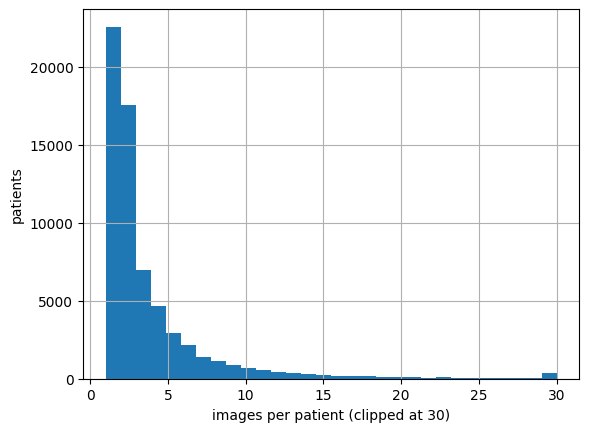

In [4]:
df['patient'] = df.Path.str.extract(r'(patient\d+)')
df['study']   = df.Path.str.extract(r'(study\d+)')

print('images:', len(df), '| patients:', df.patient.nunique())
per_patient = df.groupby('patient').size()
print(per_patient.describe())

per_patient.clip(upper=30).hist(bins=30)
plt.xlabel('images per patient (clipped at 30)'); plt.ylabel('patients'); plt.show()

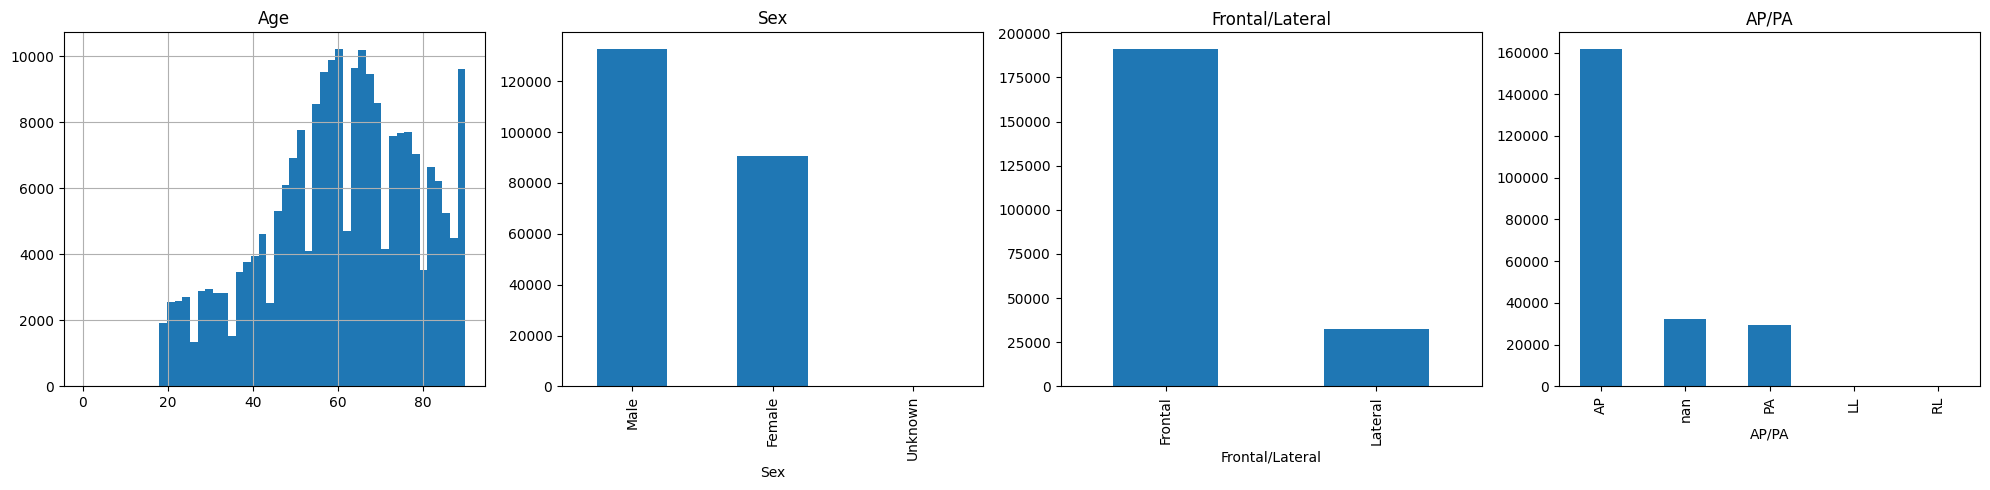

count    223414.000000
mean         60.430653
std          17.820925
min           0.000000
25%          49.000000
50%          62.000000
75%          74.000000
max          90.000000
Name: Age, dtype: float64
3 rows under 18


In [5]:
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
df.Age.hist(bins=50, ax=ax[0]); ax[0].set_title('Age')
df.Sex.value_counts(dropna=False).plot.bar(ax=ax[1], title='Sex')
df['Frontal/Lateral'].value_counts(dropna=False).plot.bar(ax=ax[2], title='Frontal/Lateral')
df['AP/PA'].value_counts(dropna=False).plot.bar(ax=ax[3], title='AP/PA')
plt.tight_layout(); plt.show()

print(df.Age.describe())
print((df.Age < 18).sum(), 'rows under 18')

In [6]:
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique())


Path:
['CheXpert-v1.0-small/train/patient00001/study1/view1_frontal.jpg'
 'CheXpert-v1.0-small/train/patient00002/study2/view1_frontal.jpg'
 'CheXpert-v1.0-small/train/patient00002/study1/view1_frontal.jpg' ...
 'CheXpert-v1.0-small/train/patient64538/study1/view1_frontal.jpg'
 'CheXpert-v1.0-small/train/patient64539/study1/view1_frontal.jpg'
 'CheXpert-v1.0-small/train/patient64540/study1/view1_frontal.jpg']

Sex:
['Female' 'Male' 'Unknown']

Age:
[68 87 83 41 20 33 42 69 81 76 50 22 19 61 55 36 43 54 56 44 46 63 59 62
 67 78 64 70 71 37 74 88 89 85 45 60 38 75 49 90 86 72 48 65 27 66 35 29
 80 79 39 25 51 18 77 53 23 31 21 40 58 84 47 52 82 73 30 57 24 28 32 34
 26  0]

Frontal/Lateral:
['Frontal' 'Lateral']

AP/PA:
['AP' nan 'PA' 'LL' 'RL']

No Finding:
[ 1. nan]

Enlarged Cardiomediastinum:
[nan  0.  1. -1.]

Cardiomegaly:
[nan -1.  0.  1.]

Lung Opacity:
[nan  1.  0. -1.]

Lung Lesion:
[nan  1. -1.  0.]

Edema:
[nan -1.  1.  0.]

Consolidation:
[nan -1.  0.  1.]

Pneumonia:
[nan 

In [7]:
# handle the Nan columns
summary = pd.DataFrame({c: df[c].value_counts(dropna=False) for c in label_cols}).T
summary = summary.fillna(0).astype(int)
summary.columns = summary.columns.fillna('NaN')
display(summary)

allowed = {1.0, 0.0, -1.0}
for c in label_cols:
    assert set(df[c].dropna().unique()) <= allowed, c

,-1.0,0.0,1.0,NaN
No Finding,0,0,22381,201033
Enlarged Cardiomediastinum,12403,21638,10798,178575
Cardiomegaly,8087,11116,27000,177211
Lung Opacity,5598,6599,105581,105636
Lung Lesion,1488,1270,9186,211470
Edema,12984,20726,52246,137458
Consolidation,27742,28097,14783,152792
Pneumonia,18770,2799,6039,195806
Atelectasis,33739,1328,33376,154971
Pneumothorax,3145,56341,19448,144480


In [8]:
# blank rate + all-3-blank
print(df[LABELS].isna().mean().round(3))
all_blank = df[LABELS].isna().all(axis=1)
print('all 3 blank:', all_blank.sum(), f'({all_blank.mean():.3f})')



Cardiomegaly        0.793
Pleural Effusion    0.404
Atelectasis         0.694
dtype: float64
all 3 blank: 52700 (0.236)


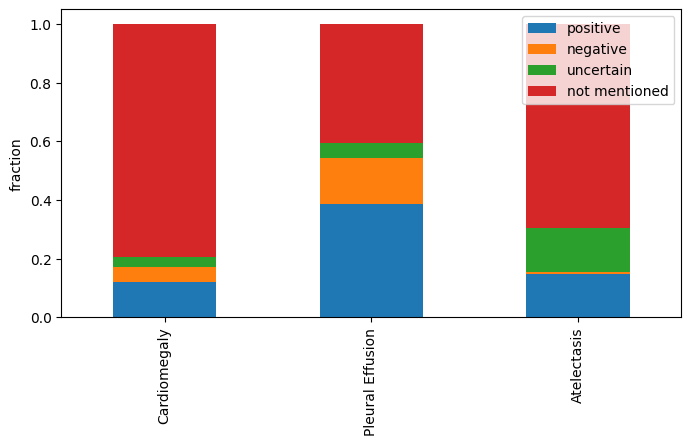

In [9]:
# stacked bar of the 4 states for our targeted 3 labels
state = pd.DataFrame({
    l: df[l].map({1: 'positive', 0: 'negative', -1: 'uncertain'}).fillna('not mentioned')
         .value_counts(normalize=True)
    for l in LABELS
}).T[['positive', 'negative', 'uncertain', 'not mentioned']]
state.plot.bar(stacked=True, figsize=(8, 4)); plt.ylabel('fraction'); plt.show()

In [10]:
# prevalence two ways
for l in LABELS:
    pos = (df[l] == 1).sum()
    known = df[l].isin([0, 1]).sum()
    print(f'{l:18s} positive/all = {pos/len(df):.3f} | positive/known(0,1) = {pos/known:.3f} | uncertain = {(df[l]==-1).mean():.3f}')

Cardiomegaly       positive/all = 0.121 | positive/known(0,1) = 0.708 | uncertain = 0.036
Pleural Effusion   positive/all = 0.386 | positive/known(0,1) = 0.709 | uncertain = 0.052
Atelectasis        positive/all = 0.149 | positive/known(0,1) = 0.962 | uncertain = 0.151


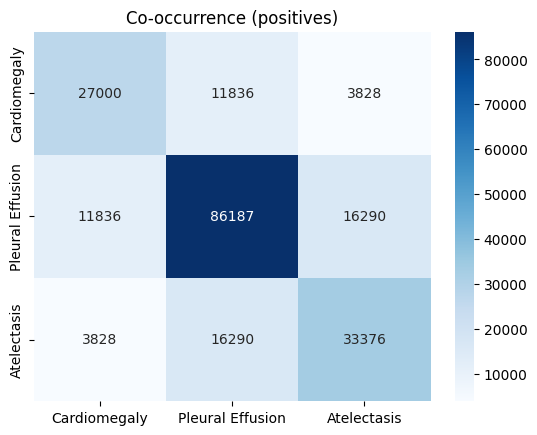

0    106771
1     88757
2     25852
3      2034
Name: count, dtype: int64
No Finding & any of 3 positive: 0


In [11]:
pos = (df[LABELS] == 1).astype(int)
co = pos.T.dot(pos)
sns.heatmap(co, annot=True, fmt='d', cmap='Blues'); plt.title('Co-occurrence (positives)'); plt.show()

print(pos.sum(axis=1).value_counts().sort_index())   # how many of the 3 labels per image
print('No Finding & any of 3 positive:', ((df['No Finding'] == 1) & (pos.sum(axis=1) > 0)).sum())

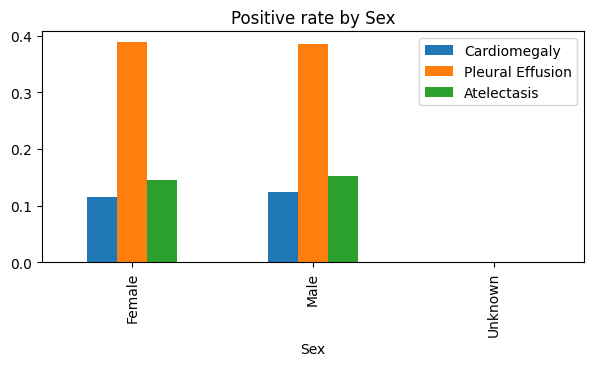

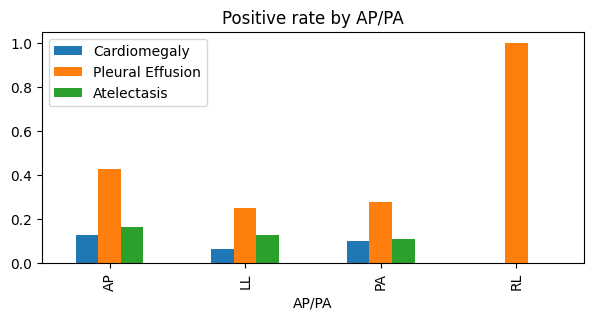

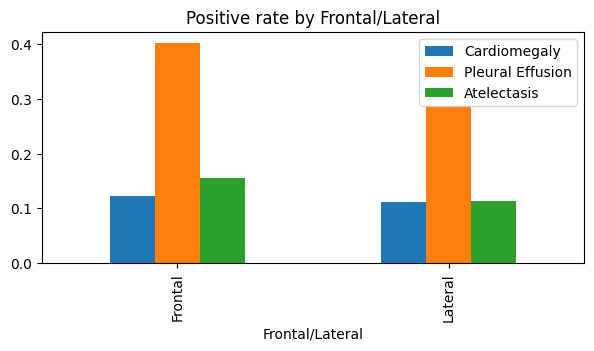

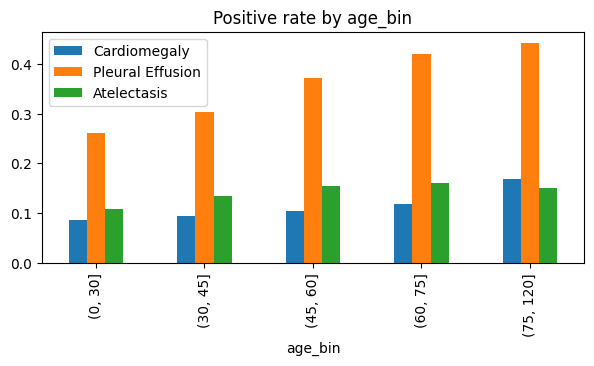

In [12]:
df['age_bin'] = pd.cut(df.Age, [0, 30, 45, 60, 75, 120])
for col in ['Sex', 'AP/PA', 'Frontal/Lateral', 'age_bin']:
    rate = (df[LABELS] == 1).groupby(df[col], observed=True).mean()
    rate.plot.bar(figsize=(7, 3), title=f'Positive rate by {col}'); plt.show()

In [13]:
print(pd.crosstab(df['Support Devices'].fillna(-9), df['Pleural Effusion'].fillna(-9), normalize='index').round(3))

Pleural Effusion   -9.0   -1.0    0.0    1.0
Support Devices                             
-9.0              0.421  0.058  0.218  0.303
-1.0              0.427  0.047  0.176  0.349
 0.0              0.438  0.039  0.109  0.414
 1.0              0.387  0.048  0.109  0.456


In [14]:
# studies per patient + heavy patients
ipp = df.groupby('patient').size()
spp = df.groupby('patient').study.nunique()
print(spp.describe())
print(ipp.sort_values(ascending=False).head(10))
heavy = ipp[ipp >= 50]
print(len(heavy), 'patients with 50+ images =', round(heavy.sum() / len(df), 4), 'of all rows')

# age outliers
print('age 0:', (df.Age == 0).sum(), '| age >= 90:', (df.Age >= 90).sum(), '| age NaN:', df.Age.isna().sum())

count    64540.000000
mean         2.907360
std          4.189741
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max         91.000000
Name: study, dtype: float64
patient
patient28746    92
patient33155    92
patient04462    89
patient24163    86
patient34615    85
patient19317    80
patient05702    79
patient13011    79
patient14282    77
patient10970    76
dtype: int64
65 patients with 50+ images = 0.0185 of all rows
age 0: 3 | age >= 90: 7579 | age NaN: 0


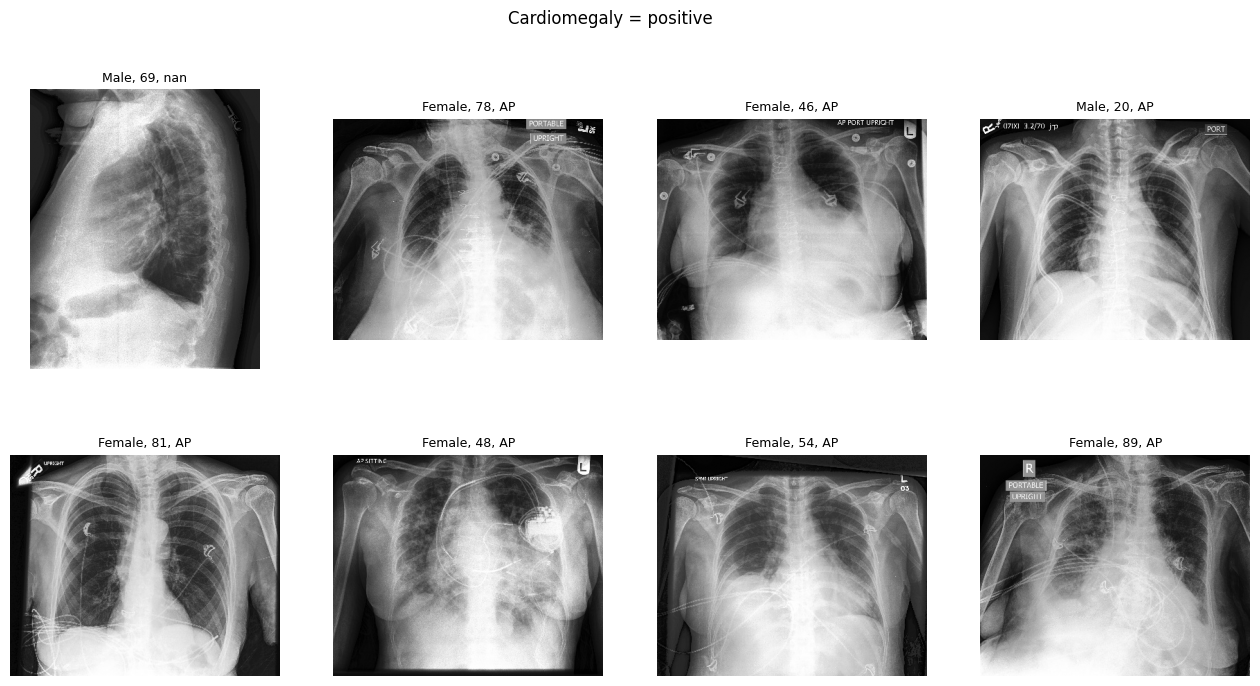

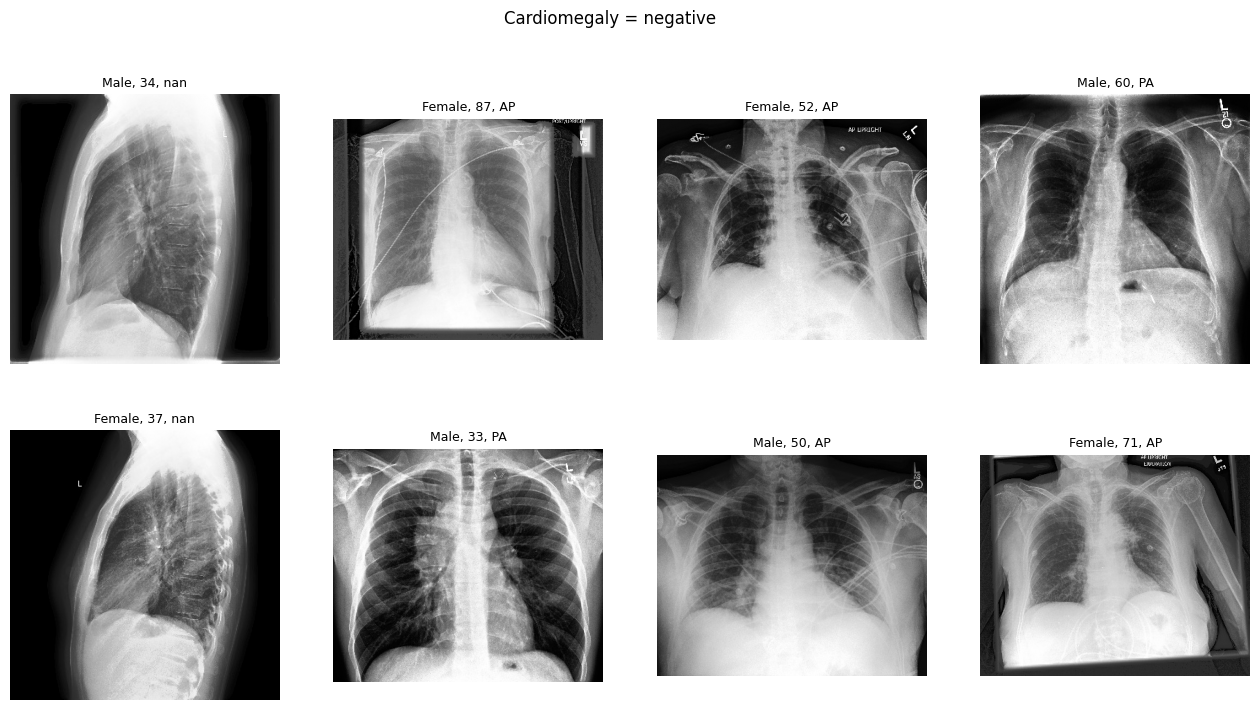

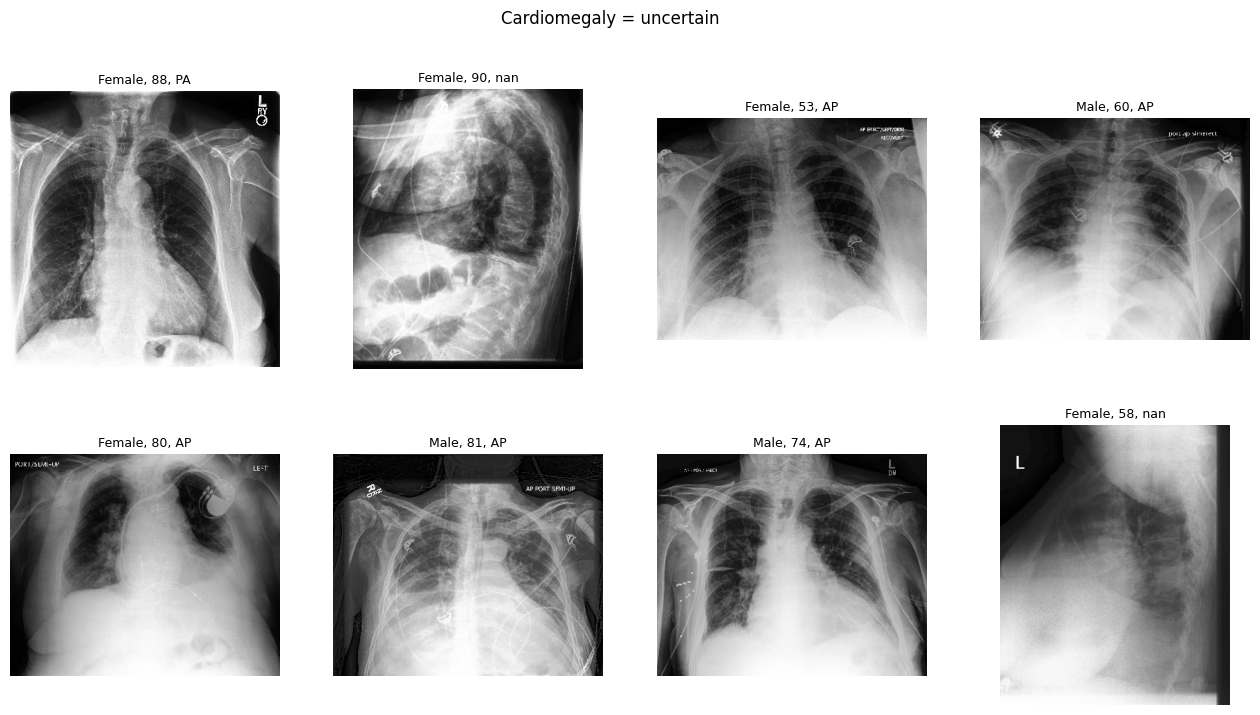

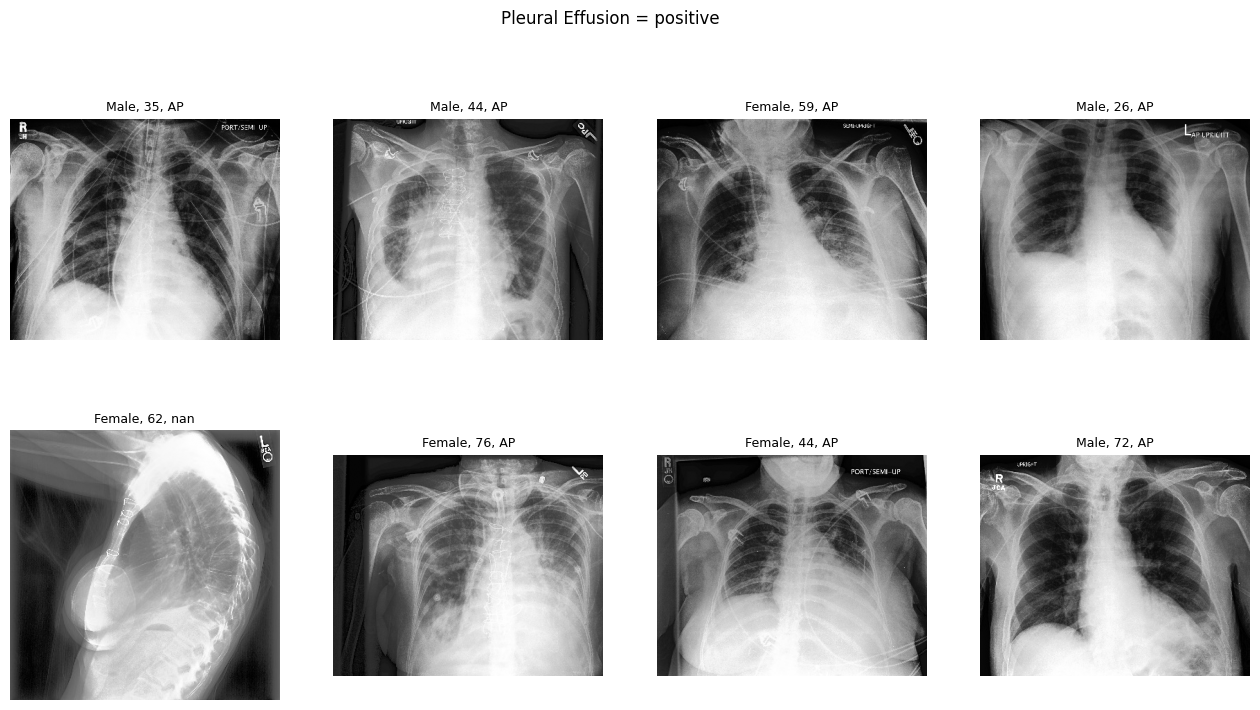

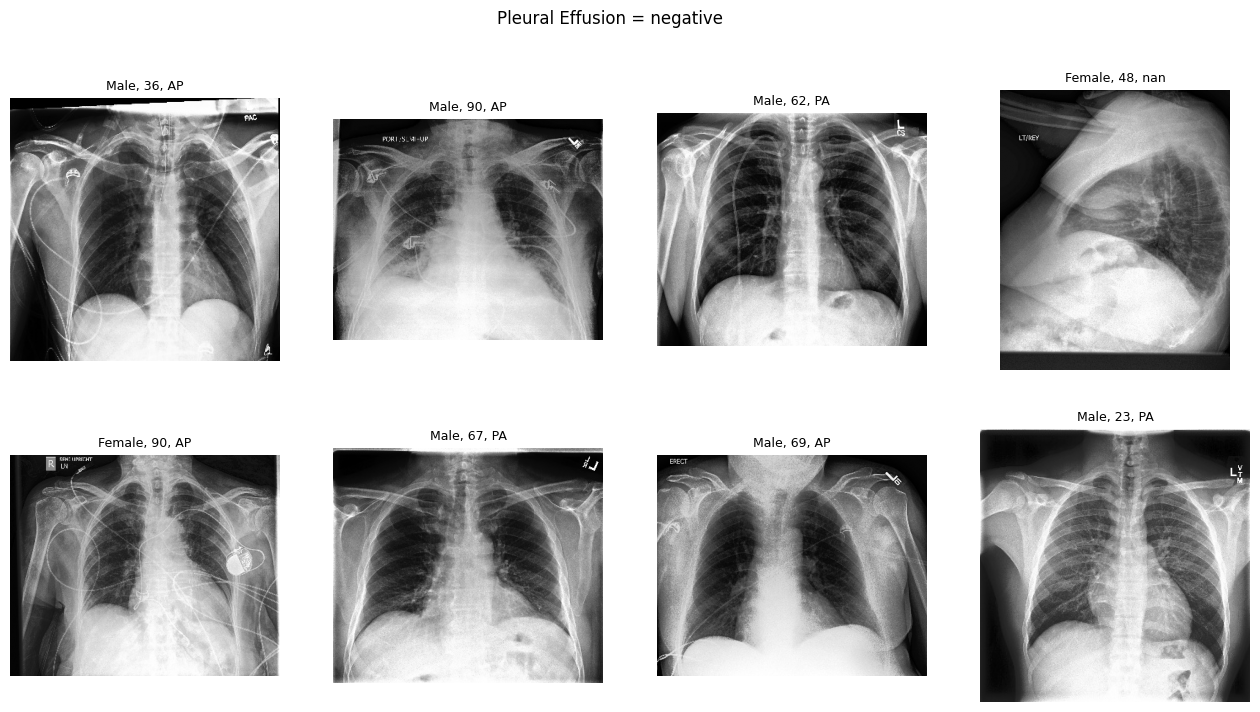

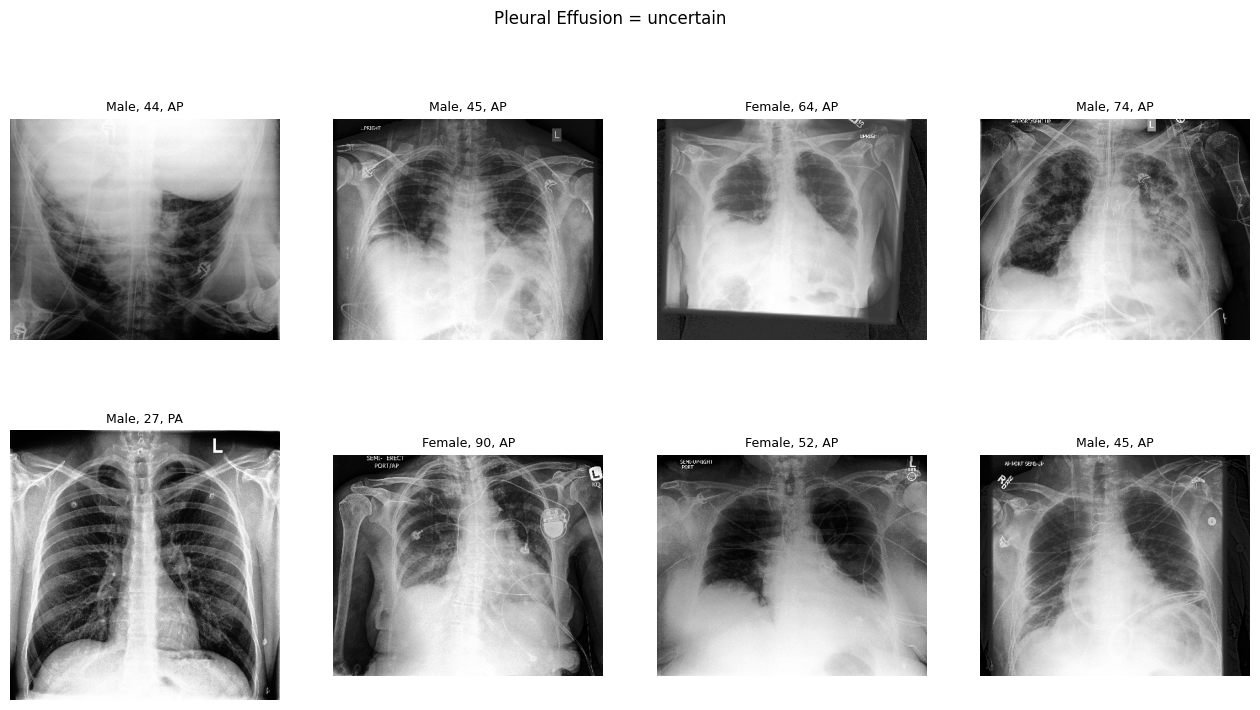

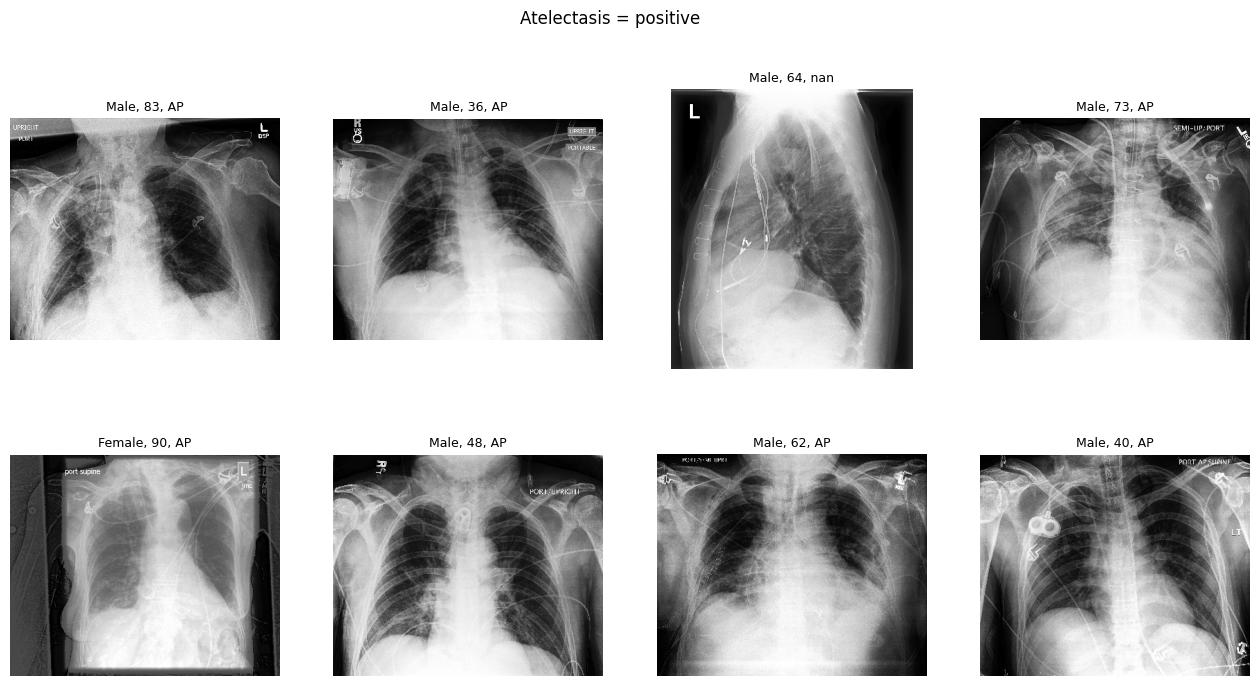

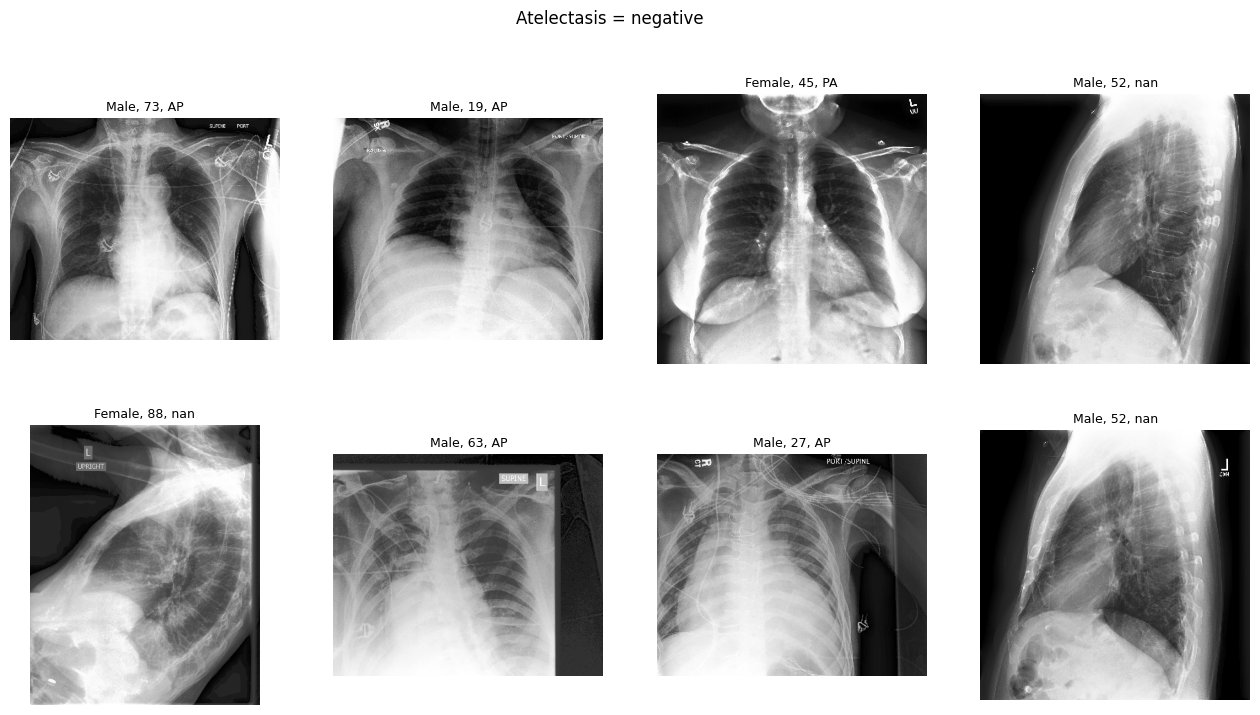

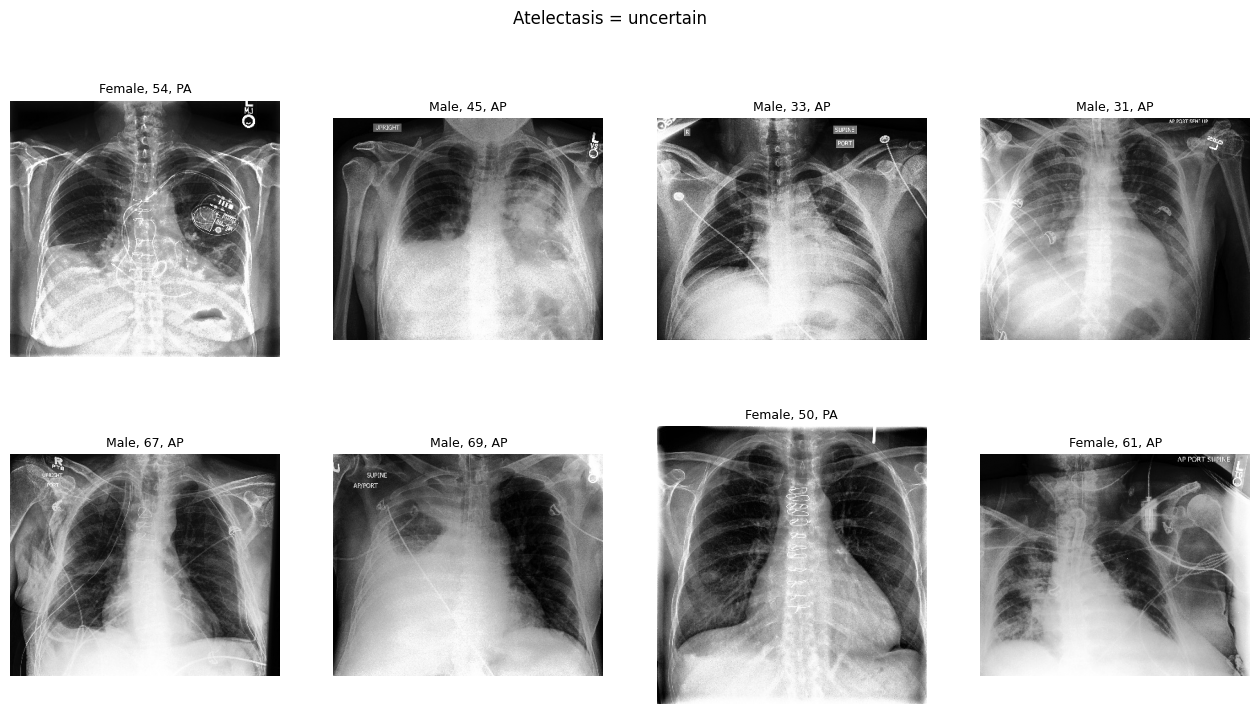

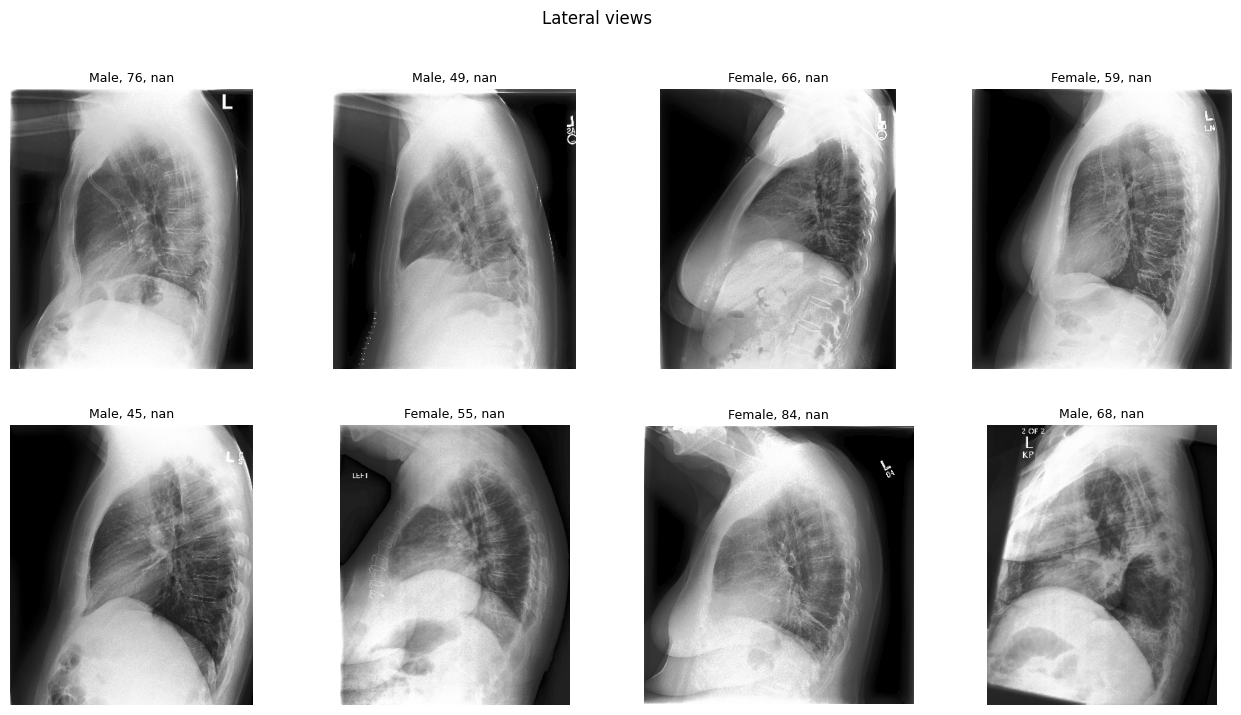

In [15]:
def show(rows, title):
    fig, ax = plt.subplots(2, 4, figsize=(16, 8))
    for a, (_, r) in zip(ax.ravel(), rows.iterrows()):
        a.imshow(Image.open(r.img_path).convert('L'), cmap='gray')
        a.set_title(f"{r['Sex']}, {r['Age']}, {r['AP/PA']}", fontsize=9); a.axis('off')
    fig.suptitle(title); plt.show()

for l in LABELS:
    show(df[df[l] == 1].sample(8, random_state=0), f'{l} = positive')
    show(df[df[l] == 0].sample(8, random_state=0), f'{l} = negative')
    show(df[df[l] == -1].sample(8, random_state=0), f'{l} = uncertain')
show(df[df['Frontal/Lateral'] == 'Lateral'].sample(8, random_state=0), 'Lateral views')

unreadable: 0
w    h  
390  320    3526
389  320     573
320  320     332
369  320     110
371  320      50
Name: count, dtype: int64 
 ar
1.22    4099
1.00     353
1.15     126
1.16      70
1.20      29
Name: count, dtype: int64
mode
L    5000
Name: count, dtype: int64
dataset mean=0.5063, std=0.2895


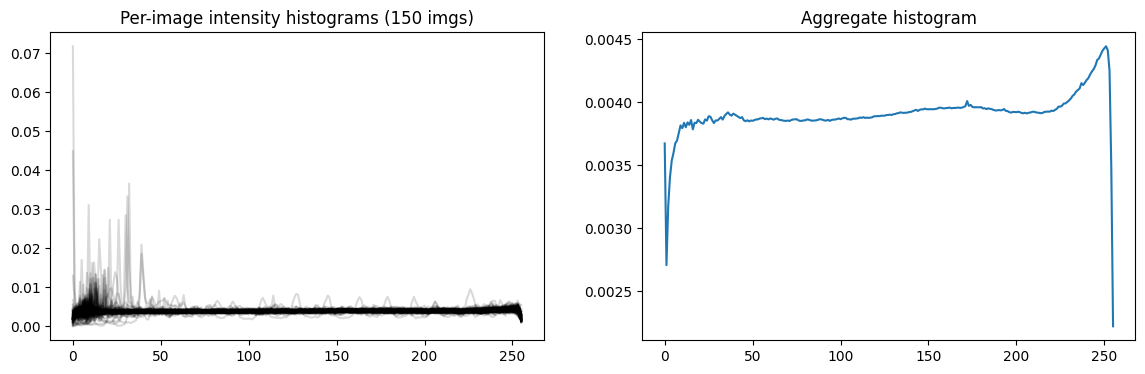

flagged: 0


In [16]:
frontal = df[df['Frontal/Lateral'] == 'Frontal']
sample = frontal.sample(5000, random_state=0)   # raise to 10000 if it's fast enough

rows, bad = [], []
agg = np.zeros(256)          # aggregate pixel histogram
per_img = []                 # per-image histograms for the first 150 images
for i, p in enumerate(sample.img_path):
    try:
        im = Image.open(p); im.load()
        a = np.asarray(im.convert('L'))
        h = np.bincount(a.ravel(), minlength=256)
        agg += h
        if i < 150: per_img.append(h / h.sum())
        rows.append(dict(path=p, w=im.width, h=im.height, ar=im.width / im.height,
                         mode=im.mode, mean=a.mean(), std=a.std(), min=a.min(), max=a.max()))
    except Exception:
        bad.append(p)

st = pd.DataFrame(rows)
print('unreadable:', len(bad))
print(st[['w', 'h']].value_counts().head(), '\n', st.ar.round(2).value_counts().head())
print(st['mode'].value_counts())

# dataset-level normalization stats from the aggregate histogram
v = np.arange(256)
mu = (v * agg).sum() / agg.sum()
sd = np.sqrt((((v - mu) ** 2) * agg).sum() / agg.sum())
print(f'dataset mean={mu/255:.4f}, std={sd/255:.4f}')

# intensity histograms
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for h in per_img: ax[0].plot(h, alpha=0.15, color='k')
ax[0].set_title('Per-image intensity histograms (150 imgs)')
ax[1].plot(agg / agg.sum()); ax[1].set_title('Aggregate histogram')
plt.show()

# blank / near-black / flat images (thresholds are heuristic, check what they catch)
flag = st[(st['mean'] < 20) | (st['std'] < 10) | ((st['max'] - st['min']) < 100)]
print('flagged:', len(flag))
if len(flag):
    fig, ax = plt.subplots(2, 4, figsize=(16, 8))
    for a_, p in zip(ax.ravel(), flag.path.head(8)):
        a_.imshow(Image.open(p).convert('L'), cmap='gray'); a_.axis('off')
    plt.show()

In [17]:
valid = pd.read_csv(ROOT + 'valid.csv')
valid['patient'] = valid.Path.str.extract(r'(patient\d+)')

print(valid.shape, '| patients:', valid.patient.nunique())
print('patient overlap with train:', len(set(valid.patient) & set(df.patient)))
print(valid[LABELS].apply(lambda s: s.value_counts(dropna=False)).T)

cmp = pd.DataFrame({'train': (df[LABELS] == 1).mean(), 'valid': (valid[LABELS] == 1).mean()})
display(cmp.round(3))

(234, 20) | patients: 200
patient overlap with train: 0
                  0.0  1.0
Cardiomegaly      166   68
Pleural Effusion  167   67
Atelectasis       154   80


,train,valid
Cardiomegaly,0.121,0.291
Pleural Effusion,0.386,0.286
Atelectasis,0.149,0.342


In [18]:
ipp = df.groupby('patient').size()   # true (unclipped) images per patient

print(ipp.describe())                # max = the real extreme
print(ipp.sort_values(ascending=False).head(10))

for t in [10, 20, 30, 50]:
    n = (ipp >= t).sum()
    share = ipp[ipp >= t].sum() / len(df)
    print(f'>= {t:2d} images: {n:5d} patients ({n / len(ipp):.2%} of patients) -> {share:.2%} of all images')

count    64540.000000
mean         3.461636
std          4.659706
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max         92.000000
dtype: float64
patient
patient28746    92
patient33155    92
patient04462    89
patient24163    86
patient34615    85
patient19317    80
patient05702    79
patient13011    79
patient14282    77
patient10970    76
dtype: int64
>= 10 images:  4207 patients (6.52% of patients) -> 31.87% of all images
>= 20 images:   987 patients (1.53% of patients) -> 13.12% of all images
>= 30 images:   340 patients (0.53% of patients) -> 6.39% of all images
>= 50 images:    65 patients (0.10% of patients) -> 1.85% of all images
